# TSARA, Phase 7 — ratios

**A walkthrough you can run, change and try to break.** Every number and figure
below is produced by the package from points drawn inside this notebook, where
the true ratio is known. No real measurement is read, and nothing needs
mounting.

---

## How to use this notebook

1. **Run everything once** (*Run All*, under a minute).
2. **Every section stands on its own.** Each opens with a **parameters cell**:
   a short list of CAPITALISED names, each commented with what it controls.
   Change a value, then run that section's cells from the parameters cell down
   to the next heading. Sections share only the setup cell below.
3. **Every section prints checks.** A line beginning ✔ is a claim about TSARA,
   compared *as it ran* against something written independently in this
   notebook: York's paper written out as a plain loop, a closed form, or the
   truth the points were drawn from. The checks are written to hold at *any*
   parameters. If you ever see ✘, you have found an edge case worth
   understanding or a bug.
4. **"Try it"** notes after each section suggest a change and say what should
   happen. Each prediction was run before this notebook was committed.
5. **The last section** collects every check into one scoreboard.

---

## What this phase delivers so far

An enhancement ratio is the slope of one gas's enhancement against another's,
over a stretch of readings: plot the event on a 1:1 chart and fit a line.
Phase 7a builds the line (`tsara.ratios`, `METHODS.md` §4):

| | Property | Section |
|---|---|---|
| 1 | **Noise on both gases**: least squares reads the ratio low when the denominator gas is noisy; York's line does not | §1 |

What this phase does **not** do yet: choose which stretches to fit (7b groups
the events stage's events across the sweep), judge a fit or combine its
uncertainties (7c).

---

## Vocabulary used throughout

| term | meaning |
|---|---|
| **enhancement** Δ | a reading minus its baseline at one window and quantile (Phase 5) |
| **ratio** | the slope of the numerator gas's enhancement against the reference gas's, over one stretch of readings: here Δethane against Δmethane |
| **fit** / **group** | one straight line through one set of points; TSARA fits many at once, each row of the input labelled with the fit it belongs to |
| **σ** | a reading's declared standard error (its *precision*), on each axis |
| **least squares** (OLS) | the familiar line: it assumes the x axis is exact |
| **York's line** | the most likely line when both axes carry error, each point weighted by its σ on both (York et al. 2004) |
| **dilution** | least squares reading a slope low because of noise on x |
| **source** | an *emission* source only: a gas leak, a landfill |

---
## Setup (run this cell first)

The **toolkit**: imports, the figure style shared by notebooks 01–07, the
**reference implementations** every check compares TSARA against, the
scoreboard, and the **recipes** that draw points with a known ratio.

In [1]:
# =============================================================================
# TOOLKIT. Every section needs this cell and nothing else from other sections.
# =============================================================================
import logging

import matplotlib.pyplot as plt
import numpy as np

from tsara import setup_logging
from tsara.ratios import FitStatus, ols, york

# --- 1. figure style (identical to notebooks 01-06) --------------------------
C1, C2, C3 = "#0072b2", "#e69f00", "#009e73"  # Okabe-Ito blue, amber, green: colour-blind safe
C4 = "#cc79a7"  # Okabe-Ito purple, for a fourth series
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "normal",
        "axes.titlelocation": "left",
        "axes.labelsize": 9.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "grid.color": GRID,
        "grid.linewidth": 0.7,
        "grid.linestyle": "-",
        "legend.frameon": False,
        "legend.fontsize": 9,
        "font.size": 9.5,
        "lines.linewidth": 1.4,
        "figure.dpi": 110,
    }
)


def finish(
    ax, title=None, sub=None, ylab=None, xlab=None, legend=False, grid_axis="y", loc="upper right"
):
    """Apply the shared chrome: left-aligned title, muted subtitle, hairline grid."""
    if title:
        ax.set_title(title, pad=19 if sub else 8)
    if sub:
        ax.text(0, 1.025, sub, transform=ax.transAxes, fontsize=8.8, color=MUTED, va="bottom")
    if ylab:
        ax.set_ylabel(ylab)
    if xlab:
        ax.set_xlabel(xlab)
    if grid_axis:
        ax.grid(True, axis=grid_axis, alpha=0.9)
    ax.set_axisbelow(True)
    if legend:
        ax.legend(loc=loc)


# --- 2. reference implementations --------------------------------------------
# Written from the papers, deliberately slow and plain: one fit at a time, in
# York's own notation. They share no code with TSARA. If TSARA and these agree,
# it is because both compute the definition.


def reference_york(x, y, sx, sy, r=0.0):
    """York et al. (2004), section III, written out for one fit.

    Weights w(X) = 1/sx², w(Y) = 1/sy², α = sqrt(w(X) w(Y)). Starting from least
    squares, repeat: W = w(X) w(Y) / (w(X) + b² w(Y) − 2 b r α); X̄, Ȳ the
    W-weighted means; U = X − X̄, V = Y − Ȳ;
    β = W [U / w(Y) + b V / w(X) − (b U + V) r / α]; b = Σ W β V / Σ W β U.
    Then a = Ȳ − b X̄, and σ_b² = 1 / Σ W u², u the adjusted points' spread.
    Returns slope, intercept, slope sigma.
    """
    x, y = np.asarray(x, float), np.asarray(y, float)
    wx = np.broadcast_to(1 / np.square(sx), x.shape)
    wy = np.broadcast_to(1 / np.square(sy), x.shape)
    alpha = np.sqrt(wx * wy)
    b = np.polyfit(x, y, 1)[0]
    for _ in range(10_000):
        w = wx * wy / (wx + b * b * wy - 2 * b * r * alpha)
        u, v = x - np.sum(w * x) / np.sum(w), y - np.sum(w * y) / np.sum(w)
        beta = w * (u / wy + b * v / wx - (b * u + v) * r / alpha)
        new = np.sum(w * beta * v) / np.sum(w * beta * u)
        if abs(new - b) <= 1e-15 * abs(new):
            b = new
            break
        b = new
    w = wx * wy / (wx + b * b * wy - 2 * b * r * alpha)
    x_bar, y_bar = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    beta = w * (
        (x - x_bar) / wy + b * (y - y_bar) / wx - (b * (x - x_bar) + (y - y_bar)) * r / alpha
    )
    adjusted = x_bar + beta
    spread = adjusted - np.sum(w * adjusted) / np.sum(w)
    return b, y_bar - b * x_bar, 1 / np.sqrt(np.sum(w * spread**2))


def reference_ols(x, y):
    """Least squares from the textbook: slope Σ(x−x̄)(y−ȳ) / Σ(x−x̄)², one fit."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    dx, dy = x - x.mean(), y - y.mean()
    return np.sum(dx * dy) / np.sum(dx * dx)


# --- 3. the scoreboard -------------------------------------------------------
CHECKS = {}  # claim -> (held?, detail); the last section prints them all


def start_section(tag):
    """Forget a section's earlier checks, so re-running it replaces rather than piles up."""
    for claim in [c for c in CHECKS if c.startswith(tag + " ")]:
        del CHECKS[claim]


def check(claim, holds, detail=""):
    """Record one claim about TSARA and print whether it held just now."""
    CHECKS[claim] = (bool(holds), detail)
    mark = "✔" if holds else "✘ DOES NOT HOLD:"
    print(f"  {mark} {claim}" + (f"   [{detail}]" if detail else ""))


# --- 4. recipes ---------------------------------------------------------------
def plume_events(
    *, n_events, n_readings, peak, width_s, ratio, sigma_x, sigma_y, seed, intercept=0.0
):
    """Draw `n_events` copies of one plume, with fresh noise each time.

    One plume passing the inlet: true Δmethane rises and falls as a Gaussian of
    standard deviation `width_s` seconds and height `peak`, read once a second
    for `n_readings` seconds centred on its peak. True Δethane is `ratio` times
    it, plus `intercept` (what a baseline a little off would leave). Each
    reading gets independent Gaussian noise, `sigma_x` on methane and `sigma_y`
    on ethane. Returns the readings in long form, every event's rows labelled
    with its number, as TSARA's fits take them, and the true Δmethane.
    """
    rng = np.random.default_rng(seed)
    t = np.arange(n_readings) - (n_readings - 1) / 2
    true_x = peak * np.exp(-0.5 * (t / width_s) ** 2)
    x = true_x + sigma_x * rng.standard_normal((n_events, n_readings))
    y = intercept + ratio * true_x + sigma_y * rng.standard_normal((n_events, n_readings))
    group = np.repeat(np.arange(n_events), n_readings)
    return x.ravel(), y.ravel(), group, true_x


# A library logs nothing until asked; this prints TSARA's warnings in the notebook.
setup_logging(logging.WARNING)

print("toolkit ready")

toolkit ready


---
## 1. One event on a 1:1 chart

The idea every ratio starts from: plot the event's Δethane against its
Δmethane and fit a line; the slope is the ratio. If both gases came from one
source, the points lie on a line through the origin (the background) whose
slope is the source's ethane/methane.

**The catch is noise on the x axis.** Least squares, the familiar line,
measures how far each point misses the line *straight up*: it assumes methane
is exact and all the scatter is ethane's. Noise on ethane does no harm, it
spreads the points up and down. But noise on methane spreads them *sideways*,
and a cloud stretched sideways is a flatter cloud: least squares reads the
slope low. This is regression dilution, and it shrinks the slope by a factor
that can be written down: (the spread of the true methane) ÷ (that spread plus
the methane noise).

**York's line** measures each miss the way the error could have arisen.
Along y, a point can miss the line by its own ethane noise σy, or by its
methane noise σx carried up the line's slope b, so each point is weighted by
the inverse of σy² + b²σx². The slope appears in its own weights, so York
iterates: start from least squares, reweigh, refit, until the slope stops
moving. In the package this is `york()` in `src/tsara/ratios/estimators.py`:
the weight is one line of it, the iteration a short loop.

Below, one weak plume read once a second, noisy on both gases. The left
panels draw it once; the right panel draws the same plume 2,000 times with
fresh noise, which is what tells a method that is right on average from one
that is not.

In [2]:
# ---- PARAMETERS (section 1) ----
RATIO = 0.05  # the source's true Δethane / Δmethane, ppb per ppb (a gas leak)
PEAK = 20.0  # the plume's methane peak above background, ppb: a weak event
WIDTH_S = 10.0  # how long the plume takes to pass: its standard deviation in time, s
N_READINGS = 60  # 1 s readings in the event, centred on the peak
SIGMA_CH4 = 3.0  # methane noise per reading, ppb: the x axis
SIGMA_C2H6 = 0.3  # ethane noise per reading, ppb: the y axis
N_EVENTS = 2000  # the same plume drawn again with fresh noise, for the right-hand panel
N_SHORT = 20  # a shorter event for the second figure: methane varies less than its noise
SEED = 7

In [3]:
start_section("§1")
x, y, group, true_x = plume_events(
    n_events=N_EVENTS,
    n_readings=N_READINGS,
    peak=PEAK,
    width_s=WIDTH_S,
    ratio=RATIO,
    sigma_x=SIGMA_CH4,
    sigma_y=SIGMA_C2H6,
    seed=SEED,
)

# Every event fitted at once: each row labelled with its event's number.
by_york = york(x, y, SIGMA_CH4, SIGMA_C2H6, group)
by_ols = ols(x, y, group=group)

# What dilution predicts least squares reads: the slope shrunk by the true
# spread of methane over that spread plus the noise it picks up.
sxx_true = np.sum((true_x - true_x.mean()) ** 2)
shrink = sxx_true / (sxx_true + (N_READINGS - 1) * SIGMA_CH4**2)

# The event the left panels draw: a typical one, the draw whose least-squares
# slope is the median of them all (one draw can land anywhere; the right panel
# is what shows where each method lands on average).
k = int(np.nanargmin(np.abs(by_ols.slope - np.nanmedian(by_ols.slope))))
first = group == k
print(f"A typical event (draw {k}, {N_READINGS} readings), true ratio {RATIO}:")
print(f"  least squares  {by_ols.slope[k]:.4f}")
print(
    f"  York           {by_york.slope[k]:.4f} ± {by_york.slope_sigma[k]:.4f}"
    f"   ({by_york.iterations[k]} iterations)"
)
print(f"\nThe same plume, {N_EVENTS} times with fresh noise:")
print(f"  {'':15} {'mean':>8} {'median':>8} {'spread (sd)':>12}   σ covers the truth, 1σ / 2σ")
for name, fit in (("least squares", by_ols), ("York", by_york)):
    s, miss = fit.slope[fit.ok], np.abs(fit.slope[fit.ok] - RATIO) / fit.slope_sigma[fit.ok]
    print(
        f"  {name:15} {np.mean(s):8.4f} {np.median(s):8.4f} {np.std(s):12.4f}"
        f"   {np.mean(miss <= 1):.2f} / {np.mean(miss <= 2):.2f}"
    )
print("  (a standard error that is right covers the truth 0.68 / 0.95 of the time)")
print(f"  dilution predicts least squares reads {shrink:.3f} × {RATIO} = {shrink * RATIO:.4f}")
signal = np.std(true_x) / SIGMA_CH4 if SIGMA_CH4 else np.inf
print(f"  methane's true spread in the event is {signal:.2f} × its noise")

# --- checks -------------------------------------------------------------------
if SIGMA_CH4 > 0:
    b_ref, a_ref, s_ref = reference_york(x[first], y[first], SIGMA_CH4, SIGMA_C2H6)
    check(
        "§1 York's line through one event is York's paper written out by hand",
        np.allclose(
            [by_york.slope[k], by_york.intercept[k], by_york.slope_sigma[k]],
            [b_ref, a_ref, s_ref],
            rtol=1e-9,
        ),
        f"slope {by_york.slope[k]:.6f} vs {b_ref:.6f}",
    )
else:
    # York's paper weighs by 1/σ², which an exact axis makes infinite; TSARA
    # writes the weights in variances, and then York with an exact x and one σy
    # for every point is least squares, every event, to rounding.
    check(
        "§1 with methane exact, York's line is least squares, every event",
        np.allclose(by_york.slope, by_ols.slope, rtol=1e-12, equal_nan=True),
    )
check(
    "§1 least squares through one event is the textbook formula",
    np.isclose(by_ols.slope[k], reference_ols(x[first], y[first]), rtol=1e-10),
)
# A fit holds a line, or holds NaN and says why: never a NaN that claims OK.
allowed = [FitStatus.OK, FitStatus.NOT_CONVERGED] if N_READINGS >= 3 else [FitStatus.TOO_FEW_POINTS]
check(
    "§1 every event's York fit holds a line or says why not",
    np.all(np.isin(by_york.status, allowed)) and np.all(np.isfinite(by_york.slope) == by_york.ok),
    f"{np.count_nonzero(by_york.ok)} of {N_EVENTS} fitted",
)
if N_READINGS >= 3:
    ols_s, york_s = by_ols.slope, by_york.slope[by_york.ok]
    # Tolerances: four standard errors of the mean (or of the median, 1.2533 × as
    # wide), plus 2 % for the finite-sample terms the large-sample formulas omit.
    tol = 4 * np.std(ols_s) / np.sqrt(ols_s.size) + 0.02 * abs(shrink * RATIO)
    check(
        "§1 least squares reads the ratio low, by the factor dilution predicts",
        abs(np.mean(ols_s) - shrink * RATIO) <= tol,
        f"mean {np.mean(ols_s):.4f}, predicted {shrink * RATIO:.4f}",
    )
    # York reads the truth when the event carries signal: methane's true spread
    # at least its noise, the range METHODS §4.5 measured. Below that no line
    # recovers a ratio (see the Try it with N_READINGS = 10).
    if signal >= 1:
        tol = 4 * 1.2533 * np.std(york_s) / np.sqrt(york_s.size) + 0.02 * abs(RATIO)
        check(
            "§1 York reads the true ratio when methane varies at least as much as its noise",
            abs(np.median(york_s) - RATIO) <= tol,
            f"median {np.median(york_s):.4f}, true {RATIO}",
        )
    else:
        print("  (methane varies less than its noise here: no claim is made about York's slope)")

A typical event (draw 696, 60 readings), true ratio 0.05:
  least squares  0.0423
  York           0.0497 ± 0.0056   (13 iterations)

The same plume, 2000 times with fresh noise:
                      mean   median  spread (sd)   σ covers the truth, 1σ / 2σ
  least squares     0.0425   0.0423       0.0056   0.35 / 0.72
  York              0.0502   0.0499       0.0068   0.61 / 0.92
  (a standard error that is right covers the truth 0.68 / 0.95 of the time)
  dilution predicts least squares reads 0.846 × 0.05 = 0.0423
  methane's true spread in the event is 2.33 × its noise
  ✔ §1 York's line through one event is York's paper written out by hand   [slope 0.049677 vs 0.049677]
  ✔ §1 least squares through one event is the textbook formula
  ✔ §1 every event's York fit holds a line or says why not   [2000 of 2000 fitted]
  ✔ §1 least squares reads the ratio low, by the factor dilution predicts   [mean 0.0425, predicted 0.0423]
  ✔ §1 York reads the true ratio when methane varies at least a

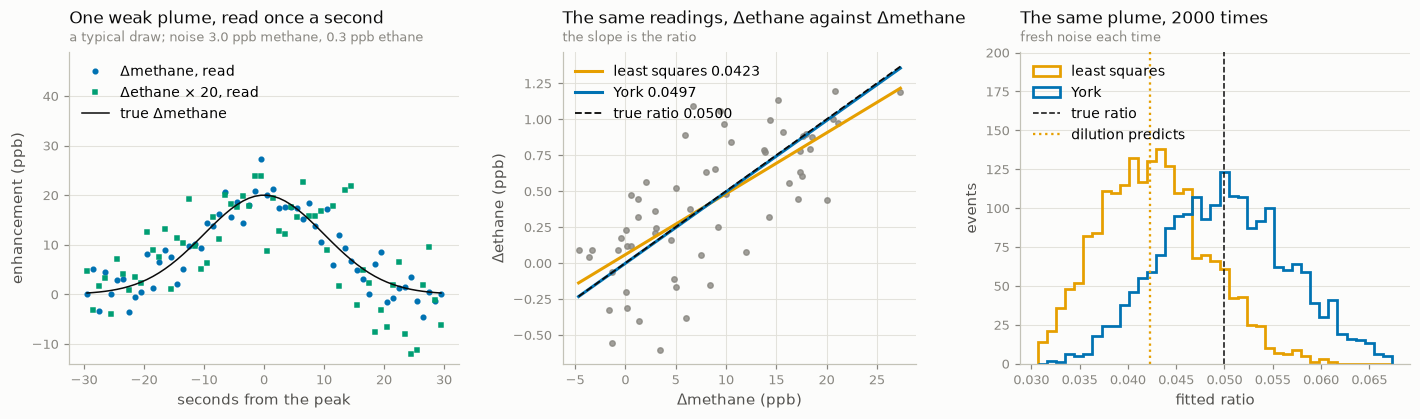

In [4]:
# Figure only.
fig, (ax_t, ax_s, ax_h) = plt.subplots(1, 3, figsize=(13, 3.9), width_ratios=[1.1, 1, 1.1])
t = np.arange(N_READINGS) - (N_READINGS - 1) / 2
gain = 1 / RATIO if RATIO else 1.0  # draw ethane on methane's scale

# (a) the event in time
ax_t.plot(t, x[first], "o", ms=3, color=C1, label="Δmethane, read")
ax_t.plot(t, gain * y[first], "s", ms=3, color=C3, label=f"Δethane × {gain:g}, read")
ax_t.plot(t, true_x, color=INK, lw=1, label="true Δmethane")
low, high = ax_t.get_ylim()
ax_t.set_ylim(low, high + 0.45 * (high - low))  # room for the legend
finish(
    ax_t,
    "One weak plume, read once a second",
    f"a typical draw; noise {SIGMA_CH4} ppb methane, {SIGMA_C2H6} ppb ethane",
    ylab="enhancement (ppb)",
    xlab="seconds from the peak",
    legend=True,
    loc="upper left",
)

# (b) the same readings on a 1:1 chart, with three lines
ax_s.plot(x[first], y[first], "o", ms=3.5, color=MUTED, alpha=0.8)
span = np.linspace(min(x[first].min(), 0), x[first].max(), 2)
ax_s.plot(
    span,
    by_ols.intercept[k] + by_ols.slope[k] * span,
    color=C2,
    lw=2,
    label=f"least squares {by_ols.slope[k]:.4f}",
)
ax_s.plot(
    span,
    by_york.intercept[k] + by_york.slope[k] * span,
    color=C1,
    lw=2,
    label=f"York {by_york.slope[k]:.4f}",
)
ax_s.plot(span, RATIO * span, "--", color=INK, lw=1.2, zorder=4, label=f"true ratio {RATIO:.4f}")
finish(
    ax_s,
    "The same readings, Δethane against Δmethane",
    "the slope is the ratio",
    ylab="Δethane (ppb)",
    xlab="Δmethane (ppb)",
    legend=True,
    loc="upper left",
    grid_axis="both",
)

# (c) many draws of the same plume
bins = np.linspace(*np.percentile(np.r_[by_ols.slope, by_york.slope[by_york.ok]], [0.5, 99.5]), 40)
counts_ols, *_ = ax_h.hist(
    by_ols.slope, bins, histtype="step", lw=1.8, color=C2, label="least squares"
)
counts_york, *_ = ax_h.hist(
    by_york.slope[by_york.ok], bins, histtype="step", lw=1.8, color=C1, label="York"
)
ax_h.set_ylim(0, 1.45 * max(counts_ols.max(), counts_york.max()))  # room for the legend
ax_h.axvline(RATIO, ls="--", color=INK, lw=1, label="true ratio")
ax_h.axvline(shrink * RATIO, ls=":", color=C2, lw=1.5, label="dilution predicts")
finish(
    ax_h,
    f"The same plume, {N_EVENTS} times",
    "fresh noise each time",
    ylab="events",
    xlab="fitted ratio",
    legend=True,
    loc="upper left",
)
fig.tight_layout()
plt.show()

**What to notice.** In the middle panel the two fitted lines pass through the
same cloud, and on one event the difference between them looks like noise.
The right panel says it is not: least squares lands, on average, exactly where
dilution predicts (the dotted line), and York lands on the truth. On a weak
plume this is a bias of tens of percent, the same direction every time, so it
does not average away over many events; it is the kind of error a campaign
mean inherits whole.

**What York needed to know.** The two σ's, one per gas, and nothing else. They
are the precisions to be declared in the manifest, and without them York fits
no line at all (it says so, `FitStatus.MISSING_SIGMA`, rather than guessing).
§4.3 and §4.5 of `METHODS.md` say what happens when they are declared at the
wrong scale.

2026-10-19 15:19:02 | WARNING  | tsara.ratios.estimators | York's slope did not settle in 1 of 2000 groups; they hold no line.


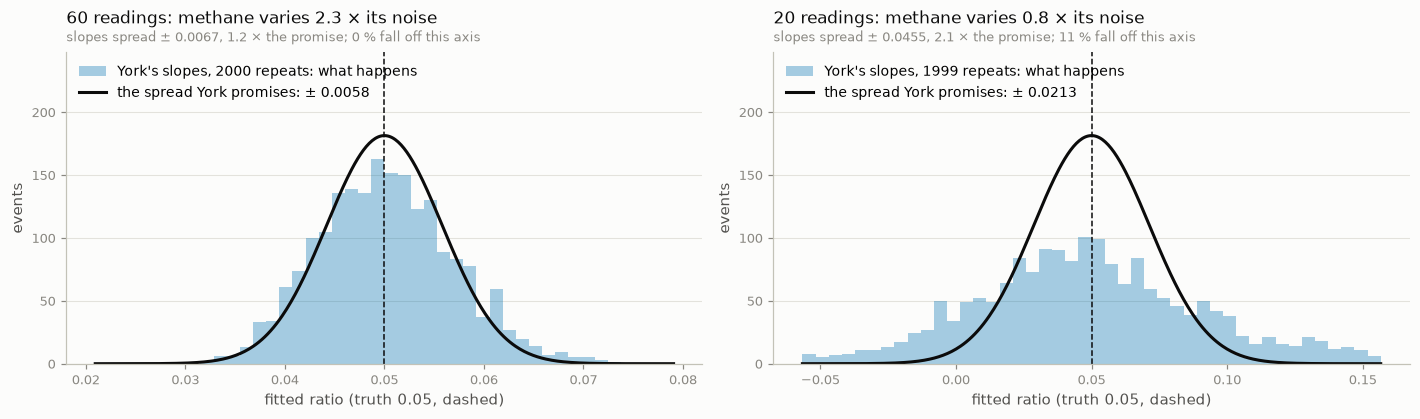

In [5]:
# Figure only: York's promised ± against how its slopes actually spread.
short_x, short_y, short_group, short_true = plume_events(
    n_events=N_EVENTS,
    n_readings=N_SHORT,
    peak=PEAK,
    width_s=WIDTH_S,
    ratio=RATIO,
    sigma_x=SIGMA_CH4,
    sigma_y=SIGMA_C2H6,
    seed=SEED,
)
by_york_short = york(short_x, short_y, SIGMA_CH4, SIGMA_C2H6, short_group)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, fit, n, truth in zip(
    axes, (by_york, by_york_short), (N_READINGS, N_SHORT), (true_x, short_true)
):
    slopes = fit.slope[fit.ok]
    promised = np.median(fit.slope_sigma[fit.ok])
    actual = 1.4826 * np.median(np.abs(slopes - np.median(slopes)))  # robust: wild misses happen
    lo, hi = RATIO - 5 * promised, RATIO + 5 * promised
    bins = np.linspace(lo, hi, 45)
    ax.hist(
        slopes[(slopes >= lo) & (slopes <= hi)],
        bins,
        color=C1,
        alpha=0.35,
        label=f"York's slopes, {slopes.size} repeats: what happens",
    )
    grid = np.linspace(lo, hi, 400)
    bell = np.exp(-0.5 * ((grid - RATIO) / promised) ** 2) / (promised * np.sqrt(2 * np.pi))
    ax.plot(
        grid,
        slopes.size * (bins[1] - bins[0]) * bell,
        color=INK,
        lw=2,
        label=f"the spread York promises: ± {promised:.4f}",
    )
    ax.axvline(RATIO, color=INK, ls="--", lw=1)
    off = np.mean((slopes < lo) | (slopes > hi))
    signal = np.std(truth) / SIGMA_CH4 if SIGMA_CH4 else np.inf
    ax.set_ylim(0, 1.3 * ax.get_ylim()[1])
    finish(
        ax,
        f"{n} readings: methane varies {signal:.1f} × its noise",
        f"slopes spread ± {actual:.4f}, {actual / promised:.1f} × the promise; "
        f"{100 * off:.0f} % fall off this axis",
        ylab="events",
        xlab=f"fitted ratio (truth {RATIO}, dashed)",
        legend=True,
        loc="upper left",
    )
fig.tight_layout()
plt.show()

York's ± is a promise about how far a repeat of the same event would land, and
the repeats above test it: at the default the slopes spread about 1.2 × wider
than promised, and on the shorter event, where methane varies less than its
noise, twice as wide with wild misses. The line stays right where there is
signal, but its ± is not to be trusted where there is little, and judging that
is 7c's (`METHODS.md` §4.5, Table 5).

**Try it**

* `SIGMA_CH4 = 0.0` — methane exact. The two lines are the same line, and both
  histograms sit on the truth: York with an exact x *is* least squares, and
  settles in one iteration.
* `PEAK = 100.0` — a strong plume. Dilution shrinks to under 1 %: least squares
  is nearly right, and York matters little. York earns its place on weak events.
* `SIGMA_C2H6 = 3.0` — ten times the ethane noise. Both histograms widen about
  tenfold and neither mean moves: noise on y costs precision, never bias.
* `N_READINGS = 10` — only the ten seconds around the peak, where true methane
  varies by a quarter of its noise. No line recovers a ratio from that: least
  squares reads near zero, York's slopes scatter without bound (median 0.014,
  mean far off, one fit that never settles) and its σ covers the truth only
  0.46 / 0.74 of the time. An event the reference gas barely moves in has no
  ratio to give, and York's own σ does not fully say so.

---
## Scoreboard

Every check printed above, gathered: each line a claim about TSARA, compared
as it ran against a reference written independently in this notebook.

In [6]:
held = sum(ok for ok, _ in CHECKS.values())
print(f"{held} of {len(CHECKS)} checks hold\n")
for claim, (ok, detail) in CHECKS.items():
    print(f"  {'✔' if ok else '✘'} {claim}" + (f"   [{detail}]" if detail else ""))

5 of 5 checks hold

  ✔ §1 York's line through one event is York's paper written out by hand   [slope 0.049677 vs 0.049677]
  ✔ §1 least squares through one event is the textbook formula
  ✔ §1 every event's York fit holds a line or says why not   [2000 of 2000 fitted]
  ✔ §1 least squares reads the ratio low, by the factor dilution predicts   [mean 0.0425, predicted 0.0423]
  ✔ §1 York reads the true ratio when methane varies at least as much as its noise   [median 0.0499, true 0.05]
